# Task 2 - MLP random search

This notebook searches for the best Normal-class precision and the best Normal-class recall using the same sampled MLP candidates. Both selected models are evaluated on the same held-out validation set, and both confusion matrices are plotted.


In [10]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, make_scorer, precision_score, recall_score
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 12
TEST_SIZE = 0.20
CV_SPLITS = 5
N_ITER = 20
SNR_LEVELS = ["SNR_noiseless", "SNR_50db", "SNR_40db", "SNR_30db", "SNR_20db"]
CLASS_NAMES = ["Normal", "Sag", "Swell", "Interruption", "Harmonics", "Sag_harmonics", "Swell_harmonics", "Transient", "Flicker"]
NORMAL_LABEL = "Normal"
FEATURE_COLUMNS = ["F1", "F2", "F3", "F4", "F5", "F6", "F7", "F8"]
RAW_TO_FEATURE = {"avg abs": "F2", "sd": "F3", "max": "F4", "min": "F5", "no. pks": "F6", "sd fma": "F7", "sd fma 3": "F1", "no. pt near 0": "F8"}

def normal_precision(y_true, y_pred):
    return precision_score(y_true, y_pred, labels=[NORMAL_LABEL], average="macro", zero_division=0)

def normal_recall(y_true, y_pred):
    return recall_score(y_true, y_pred, labels=[NORMAL_LABEL], average="macro", zero_division=0)

SCORING = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
    "normal_precision": make_scorer(normal_precision),
    "normal_recall": make_scorer(normal_recall),
}


## 1. Load the data and create one stratified train/validation split


In [11]:
def load_feature_data(data_root):
    frames = []
    for snr in SNR_LEVELS:
        snr_dir = data_root / snr
        if not snr_dir.is_dir():
            raise FileNotFoundError(f"Missing SNR directory: {snr_dir}")
        for csv_path in sorted(snr_dir.glob("*.csv")):
            label = csv_path.stem
            if label not in CLASS_NAMES:
                raise ValueError(f"Unexpected class file: {csv_path.name}")
            frame = pd.read_csv(csv_path).rename(columns=RAW_TO_FEATURE)
            missing = set(FEATURE_COLUMNS) - set(frame.columns)
            if missing:
                raise ValueError(f"{csv_path} is missing features: {sorted(missing)}")
            frame = frame[FEATURE_COLUMNS].copy()
            frame["label"] = label
            frame["snr"] = snr.removeprefix("SNR_")
            frames.append(frame)
    return pd.concat(frames, ignore_index=True)

current = Path.cwd().resolve()
DATA_ROOT = next((path / "Code" / "data" for path in [current, *current.parents] if (path / "Code" / "data").is_dir()), None)
if DATA_ROOT is None:
    raise FileNotFoundError("Could not find Code/data. Run this notebook inside the project repository.")

dataset = load_feature_data(DATA_ROOT)
X = dataset[FEATURE_COLUMNS]
y = dataset["label"]
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)
print(f"Using data from: {DATA_ROOT}")
print(f"Loaded {len(dataset):,} samples with {X.shape[1]} features.")
print(f"Training samples: {len(X_train):,}; validation samples: {len(X_valid):,}")


Using data from: /Users/felixvossbrink/Library/Mobile Documents/com~apple~CloudDocs/Uni/02 Master/01 Electrical Engineering/05 Quarter/01 Machine Learning/05 Project/EE4C12---Machine-Learning-Project/Code/data
Loaded 6,705 samples with 8 features.
Training samples: 5,364; validation samples: 1,341


## 2. Run one search for each Normal-class objective

Both searches use the same candidates and cross-validation folds; only the metric used to select and refit the best model changes.


In [12]:
PARAM_DISTRIBUTIONS = {
    "mlp__hidden_layer_sizes": [(32,), (64,), (128,), (32, 32), (64, 64), (128, 128), (32, 64, 32), (64, 128, 64), (128, 64, 32)],
    "mlp__activation": ["relu", "tanh", "logistic"],
    "mlp__solver": ["adam", "lbfgs"],
    "mlp__alpha": [1e-5, 1e-4, 1e-3, 1e-2, 1e-1],
    "mlp__learning_rate_init": [1e-4, 3e-4, 1e-3, 3e-3, 1e-2],
}

def make_search(refit_metric):
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPClassifier(batch_size=64, max_iter=500, early_stopping=False, random_state=RANDOM_STATE)),
    ])
    return RandomizedSearchCV(
        pipeline,
        PARAM_DISTRIBUTIONS,
        n_iter=N_ITER,
        scoring=SCORING,
        refit=refit_metric,
        cv=StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE),
        n_jobs=-1,
        random_state=RANDOM_STATE,
        return_train_score=False,
    )

precision_search = make_search("normal_precision")
precision_search.fit(X_train, y_train)
recall_search = make_search("normal_recall")
recall_search.fit(X_train, y_train)

def search_summary(search, metric):
    results = pd.DataFrame(search.cv_results_).sort_values(f"mean_test_{metric}", ascending=False)
    columns = ["params", "mean_test_accuracy", "mean_test_precision_macro", "mean_test_recall_macro", "mean_test_f1_macro", "mean_test_normal_precision", "mean_test_normal_recall"]
    return results[columns].head(10)

print("Best Normal precision:", precision_search.best_score_)
print("Precision-selected parameters:", precision_search.best_params_)
display(search_summary(precision_search, "normal_precision"))
print("Best Normal recall:", recall_search.best_score_)
print("Recall-selected parameters:", recall_search.best_params_)
display(search_summary(recall_search, "normal_recall"))


/Users/felixvossbrink/Library/Mobile Documents/com~apple~CloudDocs/Uni/02 Master/01 Electrical Engineering/05 Quarter/01 Machine Learning/machine-learning/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/Users/felixvossbrink/Library/Mobile Documents/com~apple~CloudDocs/Uni/02 Master/01 Electrical Engineering/05 Quarter/01 Machine Learning/machine-learning/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase t

Best Normal precision: 0.9544965090770299
Precision-selected parameters: {'mlp__solver': 'lbfgs', 'mlp__learning_rate_init': 0.0003, 'mlp__hidden_layer_sizes': (32, 64, 32), 'mlp__alpha': 0.01, 'mlp__activation': 'logistic'}


,params,mean_test_accuracy,mean_test_precision_macro,mean_test_recall_macro,mean_test_f1_macro,mean_test_normal_precision,mean_test_normal_recall
19,"{'mlp__solver': 'lbfgs', 'mlp__learning_rate_i...",0.981170,0.981264,0.981176,0.981146,0.954497,0.941289
10,"{'mlp__solver': 'lbfgs', 'mlp__learning_rate_i...",0.979865,0.979919,0.979865,0.979844,0.954001,0.937927
3,"{'mlp__solver': 'lbfgs', 'mlp__learning_rate_i...",0.986204,0.986366,0.986200,0.986224,0.949096,0.964748
7,"{'mlp__solver': 'lbfgs', 'mlp__learning_rate_i...",0.980984,0.981178,0.980985,0.980973,0.948626,0.952983
14,"{'mlp__solver': 'lbfgs', 'mlp__learning_rate_i...",0.981544,0.981711,0.981538,0.981546,0.948365,0.946275
17,"{'mlp__solver': 'lbfgs', 'mlp__learning_rate_i...",0.982290,0.982499,0.982288,0.982306,0.945589,0.953011
1,"{'mlp__solver': 'adam', 'mlp__learning_rate_in...",0.983035,0.983234,0.983030,0.983034,0.945279,0.946275
11,"{'mlp__solver': 'lbfgs', 'mlp__learning_rate_i...",0.980797,0.981027,0.980798,0.980839,0.942631,0.959734
4,"{'mlp__solver': 'lbfgs', 'mlp__learning_rate_i...",0.979120,0.979314,0.979118,0.979137,0.941919,0.944636
5,"{'mlp__solver': 'lbfgs', 'mlp__learning_rate_i...",0.982290,0.982531,0.982292,0.982330,0.941427,0.954678


Best Normal recall: 0.9697899159663865
Recall-selected parameters: {'mlp__solver': 'adam', 'mlp__learning_rate_init': 0.01, 'mlp__hidden_layer_sizes': (64,), 'mlp__alpha': 0.001, 'mlp__activation': 'relu'}


,params,mean_test_accuracy,mean_test_precision_macro,mean_test_recall_macro,mean_test_f1_macro,mean_test_normal_precision,mean_test_normal_recall
18,"{'mlp__solver': 'adam', 'mlp__learning_rate_in...",0.982476,0.982913,0.982468,0.982529,0.926665,0.969790
3,"{'mlp__solver': 'lbfgs', 'mlp__learning_rate_i...",0.986204,0.986366,0.986200,0.986224,0.949096,0.964748
11,"{'mlp__solver': 'lbfgs', 'mlp__learning_rate_i...",0.980797,0.981027,0.980798,0.980839,0.942631,0.959734
8,"{'mlp__solver': 'lbfgs', 'mlp__learning_rate_i...",0.982849,0.982983,0.982849,0.982867,0.940640,0.954720
5,"{'mlp__solver': 'lbfgs', 'mlp__learning_rate_i...",0.982290,0.982531,0.982292,0.982330,0.941427,0.954678
17,"{'mlp__solver': 'lbfgs', 'mlp__learning_rate_i...",0.982290,0.982499,0.982288,0.982306,0.945589,0.953011
7,"{'mlp__solver': 'lbfgs', 'mlp__learning_rate_i...",0.980984,0.981178,0.980985,0.980973,0.948626,0.952983
2,"{'mlp__solver': 'adam', 'mlp__learning_rate_in...",0.980238,0.980605,0.980244,0.980307,0.922337,0.949692
13,"{'mlp__solver': 'adam', 'mlp__learning_rate_in...",0.982476,0.982618,0.982476,0.982485,0.938897,0.947983
12,"{'mlp__solver': 'lbfgs', 'mlp__learning_rate_i...",0.980053,0.980285,0.980042,0.980071,0.938750,0.946303


## 3. Evaluate both models and plot both confusion matrices


Best Normal precision


,Metric,Value
0,Accuracy,0.980611
1,Macro precision,0.980891
2,Macro recall,0.980611
3,Macro F1,0.980615
4,Weighted F1,0.980615


,precision,recall,f1-score,support
Normal,0.927632,0.946309,0.936877,149.0
Sag,1.000000,0.966443,0.982935,149.0
Swell,0.993333,1.000000,0.996656,149.0
Interruption,0.973856,1.000000,0.986755,149.0
Harmonics,0.993333,1.000000,0.996656,149.0
Sag_harmonics,1.000000,1.000000,1.000000,149.0
Swell_harmonics,1.000000,1.000000,1.000000,149.0
Transient,0.953947,0.973154,0.963455,149.0
Flicker,0.985915,0.939597,0.962199,149.0


Best Normal recall


,Metric,Value
0,Accuracy,0.981357
1,Macro precision,0.982204
2,Macro recall,0.981357
3,Macro F1,0.981452
4,Weighted F1,0.981452


,precision,recall,f1-score,support
Normal,0.906250,0.973154,0.938511,149.0
Sag,1.000000,0.973154,0.986395,149.0
Swell,1.000000,1.000000,1.000000,149.0
Interruption,0.973856,1.000000,0.986755,149.0
Harmonics,1.000000,1.000000,1.000000,149.0
Sag_harmonics,1.000000,1.000000,1.000000,149.0
Swell_harmonics,1.000000,1.000000,1.000000,149.0
Transient,0.959732,0.959732,0.959732,149.0
Flicker,1.000000,0.926174,0.961672,149.0


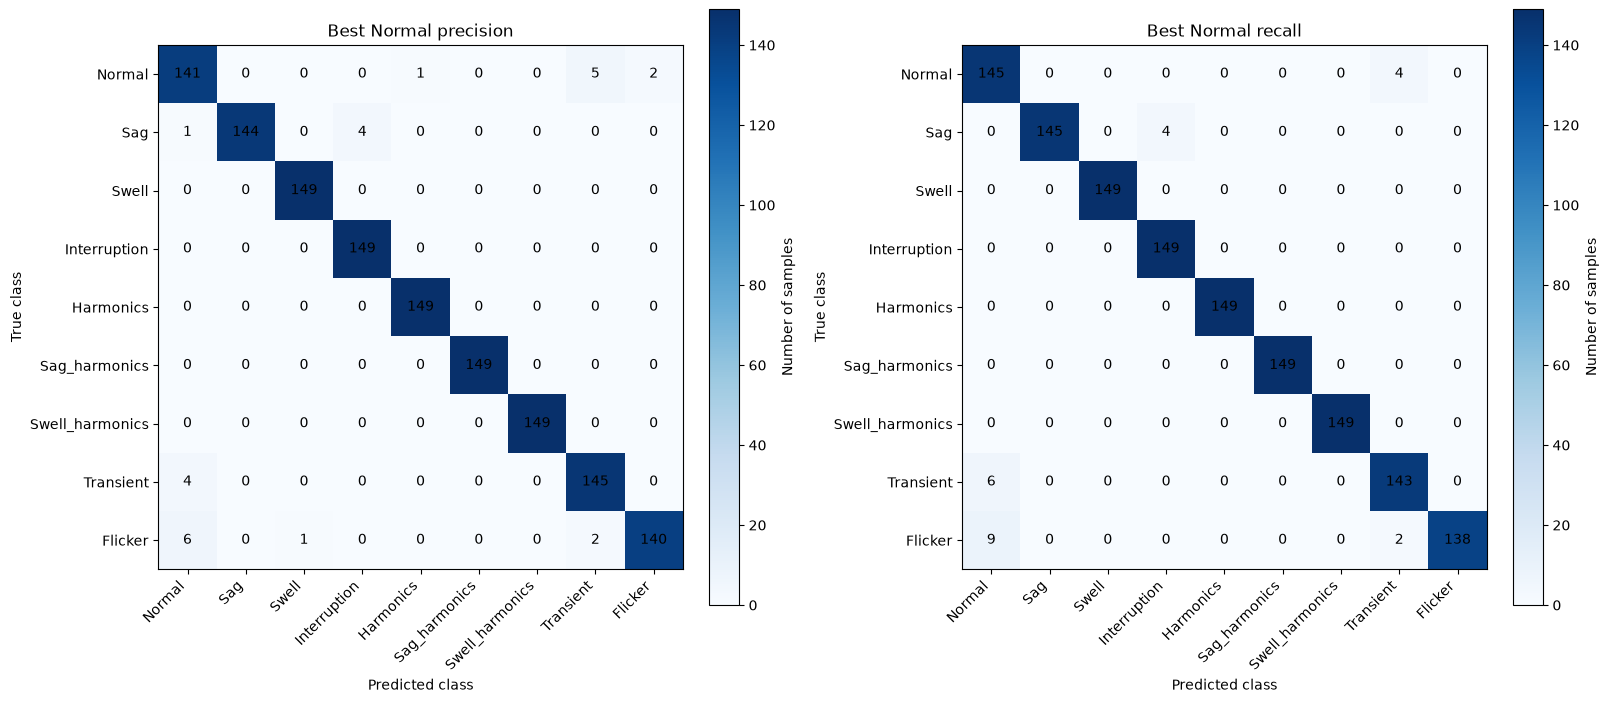

In [13]:
selected_searches = {"Best Normal precision": precision_search, "Best Normal recall": recall_search}
predictions = {title: search.best_estimator_.predict(X_valid) for title, search in selected_searches.items()}

for title, y_pred in predictions.items():
    print(title)
    metrics = pd.DataFrame({
        "Metric": ["Accuracy", "Macro precision", "Macro recall", "Macro F1", "Weighted F1"],
        "Value": [accuracy_score(y_valid, y_pred), precision_score(y_valid, y_pred, average="macro", zero_division=0), recall_score(y_valid, y_pred, average="macro", zero_division=0), f1_score(y_valid, y_pred, average="macro", zero_division=0), f1_score(y_valid, y_pred, average="weighted", zero_division=0)],
    })
    display(metrics)
    report = pd.DataFrame(classification_report(y_valid, y_pred, labels=CLASS_NAMES, output_dict=True, zero_division=0)).T
    display(report.loc[CLASS_NAMES, ["precision", "recall", "f1-score", "support"]])

fig, axes = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)
for ax, (title, y_pred) in zip(axes, predictions.items()):
    matrix = confusion_matrix(y_valid, y_pred, labels=CLASS_NAMES)
    image = ax.imshow(matrix, cmap="Blues")
    for row in range(matrix.shape[0]):
        for column in range(matrix.shape[1]):
            ax.text(column, row, matrix[row, column], ha="center", va="center")
    ax.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=45, ha="right")
    ax.set_yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.set_title(title)
    fig.colorbar(image, ax=ax, label="Number of samples")
plt.show()


## 4. Confusion matrix for the Normal-precision-selected model


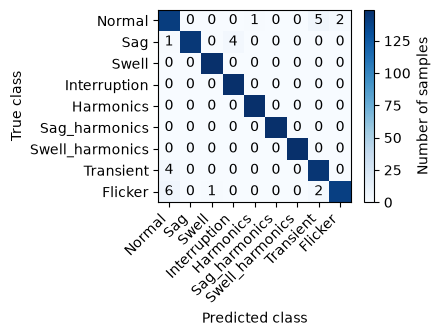

In [32]:
import sys
from matplotlib import figure
from pathlib import Path


# Get the current working directory where the notebook is running
CURRENT_DIR = Path.cwd()
REPOSITORY_ROOT = CURRENT_DIR.parents[2]  # Adjust the index (2) based on your folder depth
sys.path.insert(0, str(CURRENT_DIR))

precision_predictions = precision_search.best_estimator_.predict(X_valid)
precision_matrix = confusion_matrix(y_valid, precision_predictions, labels=CLASS_NAMES)

fig, ax = plt.subplots(figsize=(3.5, 2.5))
image = ax.imshow(precision_matrix, cmap="Blues")
for row in range(precision_matrix.shape[0]):
    for column in range(precision_matrix.shape[1]):
        if column != row:  # Only add text for off-diagonal elements
            ax.text(column, row, precision_matrix[row, column], ha="center", va="center")
ax.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=45, ha="right")
ax.set_yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
fig.colorbar(image, ax=ax, label="Number of samples")



output_path = REPOSITORY_ROOT / "Paper - IEEE" / "02_Plots" / "mlp_confusion_matrix_best_normal_precision.pdf"
output_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(output_path, bbox_inches="tight")
plt.show()